<a href="https://colab.research.google.com/github/Adhityayusuf/mesin-learning/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')

print("Ukuran dataset:", df.shape)
display(df.head())
print(df.info())
print("\nData kosong:")
print(df.isnull().sum())

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None

Data kosong:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


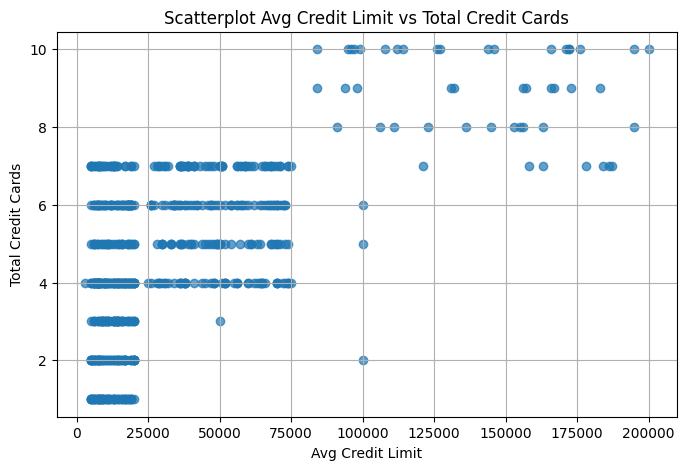

Korelasi: 0.6088604935524963


In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    alpha=0.7
)

plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.grid(True)
plt.show()

print(
    "Korelasi:",
    df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards'])
)

In [4]:
fitur_kmeans = df[
    ['Avg_Credit_Limit', 'Total_Credit_Cards']
]

scaler_kmeans = StandardScaler()
X_kmeans = scaler_kmeans.fit_transform(fitur_kmeans)

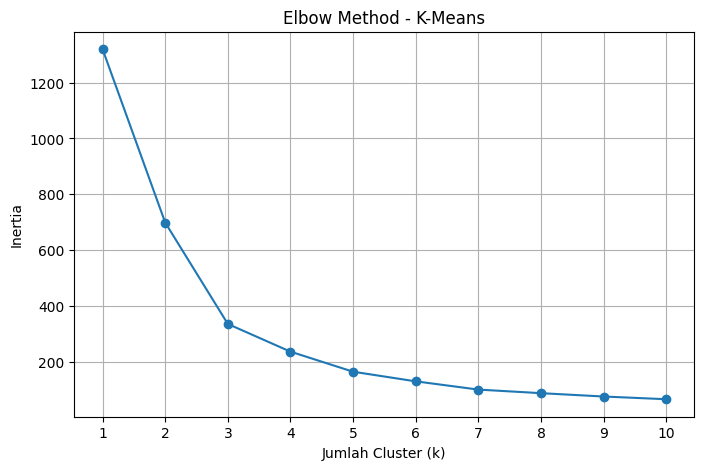

In [5]:
inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_kmeans)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - K-Means')
plt.xticks(k_values)
plt.grid(True)
plt.show()

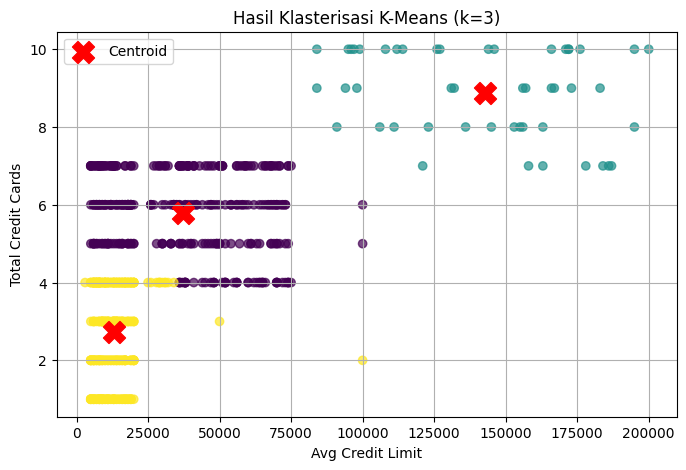

In [6]:
k_terbaik = 3

model_kmeans = KMeans(
    n_clusters=k_terbaik,
    random_state=42,
    n_init=10
)

df['Cluster_KMeans'] = model_kmeans.fit_predict(X_kmeans)

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['Cluster_KMeans'],
    cmap='viridis',
    alpha=0.7
)

centroid_asli = scaler_kmeans.inverse_transform(
    model_kmeans.cluster_centers_
)

plt.scatter(
    centroid_asli[:, 0],
    centroid_asli[:, 1],
    marker='X',
    s=250,
    color='red',
    label='Centroid'
)

plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
print(df['Cluster_KMeans'].value_counts().sort_index())

Cluster_KMeans
0    330
1     48
2    282
Name: count, dtype: int64


In [8]:
fitur_dbscan = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X_dbscan_asli = df[fitur_dbscan]

scaler_dbscan = StandardScaler()
X_dbscan = scaler_dbscan.fit_transform(X_dbscan_asli)

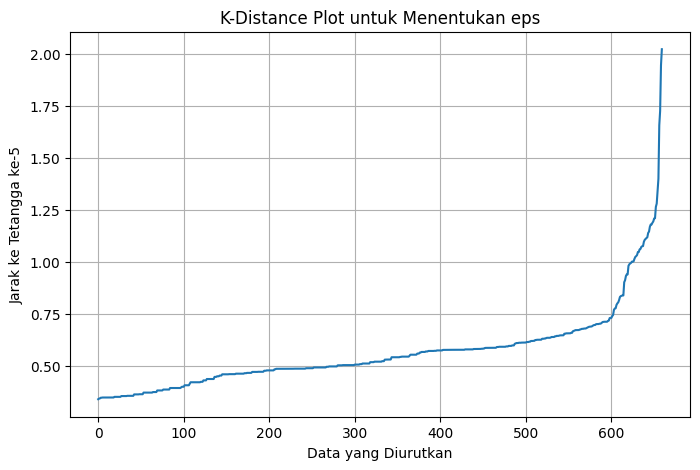

In [9]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_dbscan)

distances, indices = neighbors_fit.kneighbors(X_dbscan)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(distances)

plt.xlabel('Data yang Diurutkan')
plt.ylabel('Jarak ke Tetangga ke-5')
plt.title('K-Distance Plot untuk Menentukan eps')
plt.grid(True)
plt.show()

In [10]:
dbscan = DBSCAN(
    eps=1.2,
    min_samples=5
)

df['Cluster_DBSCAN'] = dbscan.fit_predict(X_dbscan)

print("Jumlah cluster:",
      len(set(df['Cluster_DBSCAN']) - {-1}))

print("Jumlah noise:",
      (df['Cluster_DBSCAN'] == -1).sum())

print("\nJumlah data setiap label:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

Jumlah cluster: 2
Jumlah noise: 4

Jumlah data setiap label:
Cluster_DBSCAN
-1      4
 0    608
 1     48
Name: count, dtype: int64


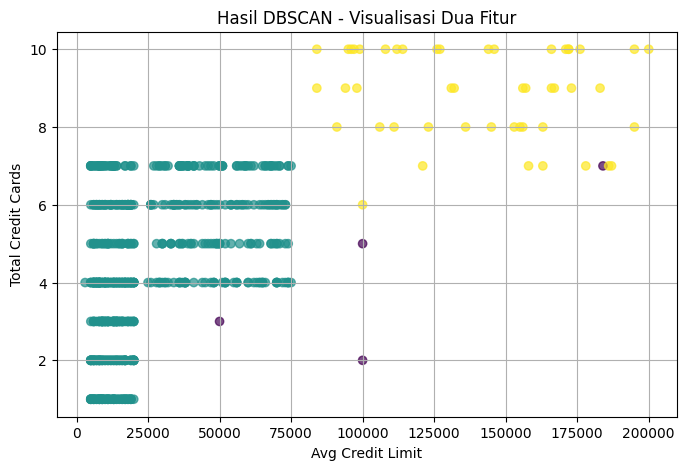

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['Cluster_DBSCAN'],
    cmap='viridis',
    alpha=0.7
)

plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.title('Hasil DBSCAN - Visualisasi Dua Fitur')
plt.grid(True)
plt.show()

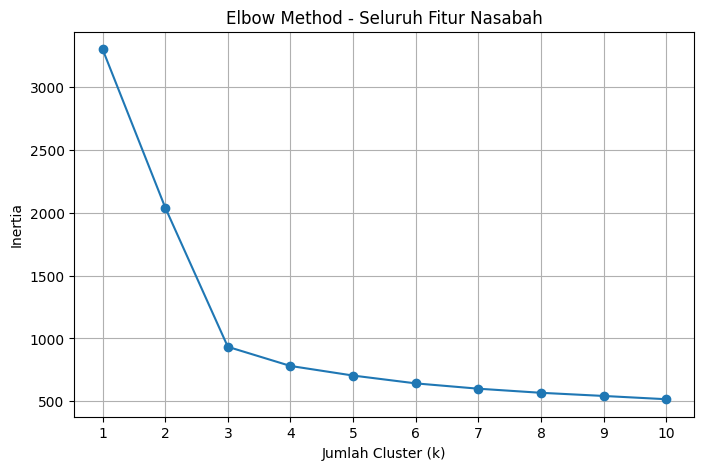

In [12]:
inertia_semua_fitur = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_dbscan)
    inertia_semua_fitur.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_semua_fitur, marker='o')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method - Seluruh Fitur Nasabah')
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [14]:
mask = df['Cluster_DBSCAN'] != -1

X_evaluasi = X_dbscan[mask]
label_evaluasi = df.loc[mask, 'Cluster_DBSCAN']

jumlah_cluster = label_evaluasi.nunique()

if jumlah_cluster >= 2:
    silhouette = silhouette_score(
        X_evaluasi,
        label_evaluasi
    )

    dbi = davies_bouldin_score(
        X_evaluasi,
        label_evaluasi
    )

    print("Silhouette Score:", silhouette)
    print("Davies-Bouldin Index:", dbi)
else:
    print("Evaluasi tidak dapat dilakukan karena cluster kurang dari 2.")

Silhouette Score: 0.5723066186731014
Davies-Bouldin Index: 0.6287828431175619
